## 기초데이터과학 (01분반)

## Lab 08. 데이터 시각화 실습 2

### 진행 방식

- **문제 단위**로 진행하며, 문제마다 제한시간이 있음
- 코드 셀의 주석을 참고하여 직접 코드를 작성할 것
- 실행 결과가 아래 **기대 출력**의 그래프와 같은 모양이면 정답
  - 색상이나 크기가 조금 달라도 괜찮음. 그래프의 종류, 축, 제목, 구분 기준이 같은지를 확인할 것
- 제한시간이 끝나면 다 같이 풀이 진행

### 실습 내용

| 문제 | 내용 | 작성할 것 |
|---|---|---|
| 1 | 두 변수의 관계 보기 | 코드 + 결과 해석 |
| 2 | 같은 조건끼리 비교하기 | 코드 + 결과 해석 |
| 3 | 여러 변수를 한 번에 보기, 나눠 그리기 | 코드 |
| 4 | pivot 과 heatmap | 코드 + 결과 해석 |

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

---

## 문제 1. 두 변수의 관계 보기 (제한시간 10분)

- 5주차, 7주차에 사용한 자동차 연비 데이터 (mpg)
- 아래 셀을 먼저 실행할 것

| 변수 | 의미 |
|---|---|
| `displ` | 배기량 (리터) |
| `year` | 출시 연도 (1999, 2008) |
| `drv` | 구동 방식 (`f`: 전륜, `r`: 후륜, `4`: 사륜) |
| `cty`, `hwy` | 도시 연비, 고속도로 연비 |
| `category` | 자동차 종류 |

In [2]:
mpg = pd.read_csv('https://raw.githubusercontent.com/tidyverse/ggplot2/main/data-raw/mpg.csv')
mpg = mpg.rename(columns={'class': 'category'})   # 수업에서 사용한 열 이름으로 맞춤

print(mpg[['displ', 'year', 'drv', 'cty', 'hwy', 'category']].head())

   displ  year drv  cty  hwy category
0    1.8  1999   f   18   29  compact
1    1.8  1999   f   21   29  compact
2    2.0  2008   f   20   31  compact
3    2.0  2008   f   21   30  compact
4    2.8  1999   f   16   26  compact


#### 1-1. 배기량(`displ`)과 고속도로 연비(`hwy`)의 관계를 회귀선이 포함된 산점도로 그리시오.

- 제목은 `Engine Size vs Highway MPG`

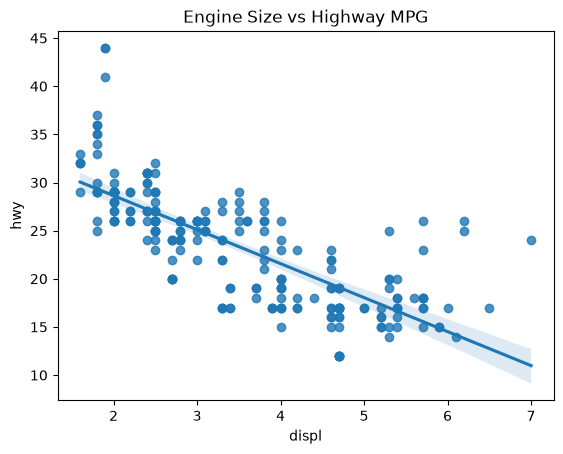

In [3]:
# 회귀선이 포함된 산점도
sns.regplot(data=mpg, x='displ', y='hwy')

# 제목
plt.title('Engine Size vs Highway MPG')
plt.show()

**기대 출력**

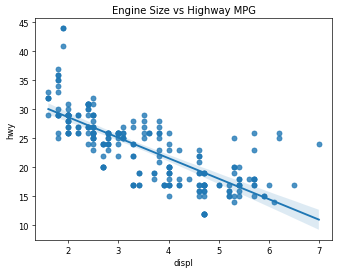


#### 1-2. 같은 두 변수의 산점도를 그리되, 구동 방식(`drv`)은 색으로, 출시 연도(`year`)는 점 모양으로 구분하시오.

- 제목은 `Engine Size vs Highway MPG by Drive Type`

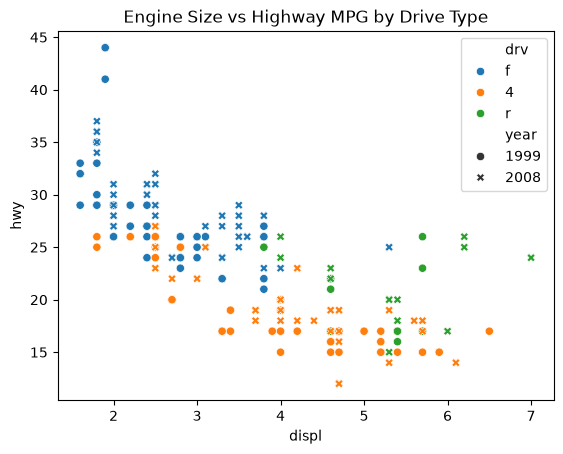

In [4]:
# 색과 점 모양으로 구분한 산점도
sns.scatterplot(data=mpg, x='displ', y='hwy', hue='drv', style='year')

# 제목
plt.title('Engine Size vs Highway MPG by Drive Type')
plt.show()

**기대 출력**

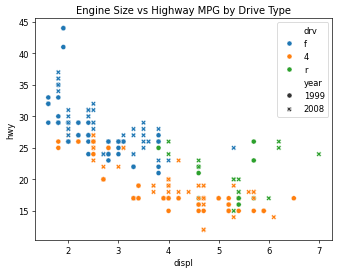


#### 1-3. 1-1, 1-2 의 그래프를 보고 아래 물음에 답하시오.

- 배기량과 고속도로 연비는 어떤 관계인가? (양의 관계 / 음의 관계 / 관계 없음)
- 배기량이 크고 연비가 낮은 오른쪽 아래 영역에는 주로 어떤 구동 방식의 차량이 있는가?

---

##### 답안

- 음의 관계, 배기량이 커질수록 고속도로 연비가 대체로 낮아진다.
- 주로 사륜구동이며 후륜구동도 일부 있다.

---

## 문제 2. 같은 조건끼리 비교하기 (제한시간 15분)

- 다이아몬드 약 5만 4천 개의 가격과 특성 데이터
- 아래 셀을 먼저 실행할 것

| 변수 | 의미 |
|---|---|
| `carat` | 무게 (캐럿). 클수록 큰 다이아몬드 |
| `cut` | 가공(컷) 품질. Fair < Good < Very Good < Premium < Ideal 순으로 좋음 |
| `color`, `clarity` | 색상 등급, 투명도 등급 |
| `price` | 가격 (달러) |

In [5]:
diamonds = sns.load_dataset('diamonds')

print(diamonds.shape)
print(diamonds[['carat', 'cut', 'color', 'clarity', 'price']].head())

(53940, 10)
   carat      cut color clarity  price
0   0.23    Ideal     E     SI2    326
1   0.21  Premium     E     SI1    326
2   0.23     Good     E     VS1    327
3   0.29  Premium     I     VS2    334
4   0.31     Good     J     SI2    335


### 아래 문제를 풀기 전에 생각해 볼 것

- 컷 품질이 가장 좋은 `Ideal` 의 **평균 가격**은 다섯 등급 중 몇 번째로 높을까?
  1. 가장 높음
  2. 중간 정도
  3. 가장 낮음

> 나의 예측: 가장 높음

#### 2-1. 컷 품질(`cut`)별 평균 가격을 막대 그래프로 그리시오.

- 오차 막대는 표시하지 않음
- 제목은 `Mean Price by Cut`

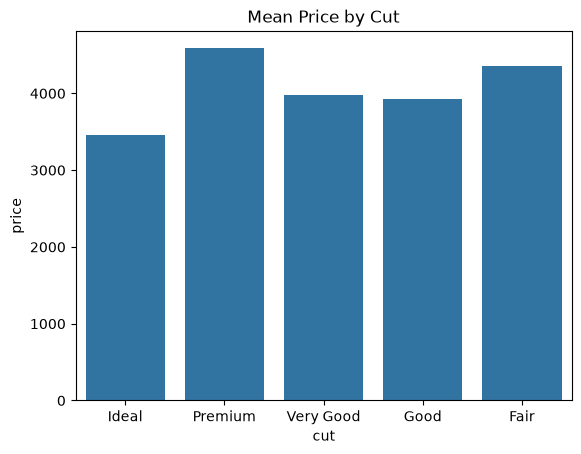

In [6]:
# 컷 품질별 평균 가격 막대 그래프
sns.barplot(data=diamonds, x='cut', y='price', errorbar=None)

# 제목
plt.title('Mean Price by Cut')
plt.show()

**기대 출력**

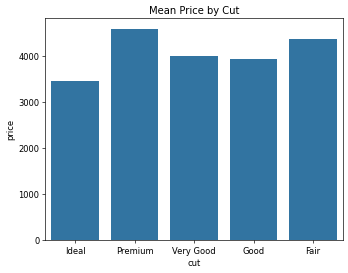


#### 2-2. 컷 품질별 평균 무게(`carat`)를 막대 그래프로 그리시오.

- 오차 막대는 표시하지 않음
- 제목은 `Mean Carat by Cut`

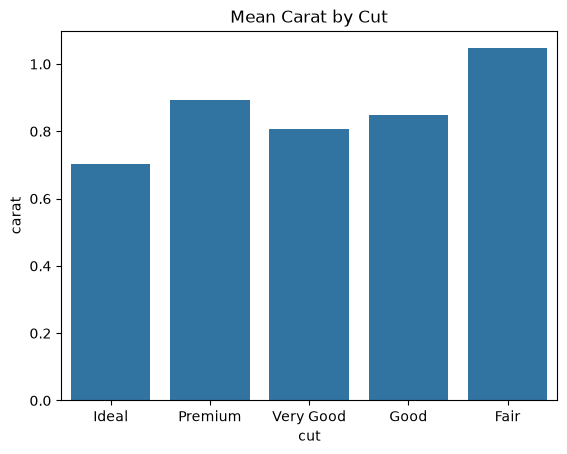

In [7]:
# 컷 품질별 평균 무게 막대 그래프
sns.barplot(data=diamonds, x='cut', y='carat', errorbar=None)

# 제목
plt.title('Mean Carat by Cut')
plt.show()

**기대 출력**

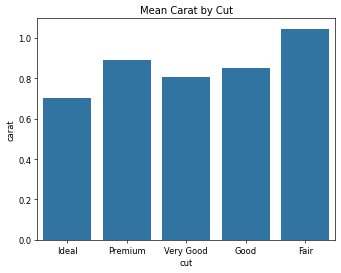


#### 2-3. 무게가 0.9 캐럿 이상 1.1 캐럿 미만인 다이아몬드만 골라, 컷 품질별 평균 가격을 막대 그래프로 그리시오.

- 오차 막대는 표시하지 않음
- 제목은 `Mean Price by Cut (0.9 - 1.1 carat)`

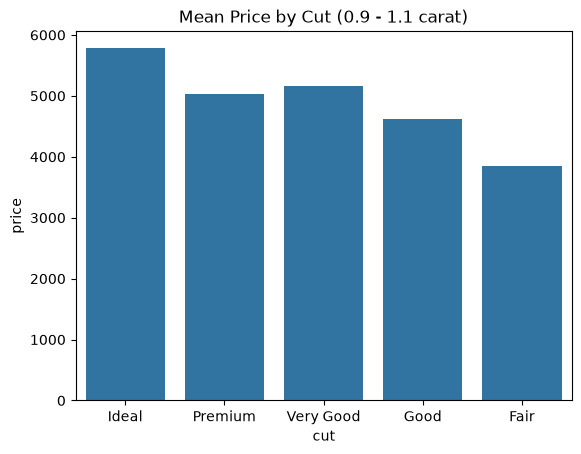

In [8]:
# 무게 조건으로 추출
diamonds_1_carat = diamonds[(diamonds['carat'] >= 0.9) & (diamonds['carat'] < 1.1)]

# 컷 품질별 평균 가격 막대 그래프
sns.barplot(data=diamonds_1_carat, x='cut', y='price', errorbar=None)

# 제목
plt.title('Mean Price by Cut (0.9 - 1.1 carat)')
plt.show()

**기대 출력**

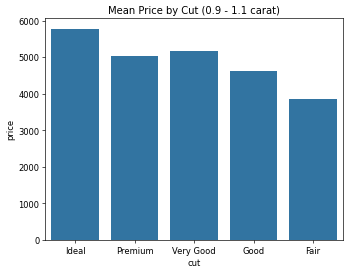


#### 2-4. 2-1 과 2-3 의 결과가 다르게 나온 이유를 2-2 의 결과를 근거로 설명하시오.

---

##### 답안

- 전체 데이터에서 `Ideal` 등급의 평균 무게가 가장 작아 평균 가격도 가장 낮게 나타난다. 
다이아몬드 무게를 0.9 이상 1.1 캐럿 미만으로 맞춰 비교하면 무게 차이의 영향이 줄어들어 `Ideal` 등급의 평균 가격이 가장 높게 나타난다.

---

## 문제 3. 여러 변수를 한 번에 보기, 나눠 그리기 (제한시간 10분)

- 문제 1 의 mpg 데이터를 사용함

#### 3-1. `displ`, `cty`, `hwy`, `drv` 네 열만 골라, 숫자형 변수의 모든 쌍에 대한 관계를 한 번에 그리시오.

- 구동 방식(`drv`)을 색으로 구분할 것

> **힌트**
> - 네 열만 골라낸 데이터프레임을 그래프 함수에 전달할 것

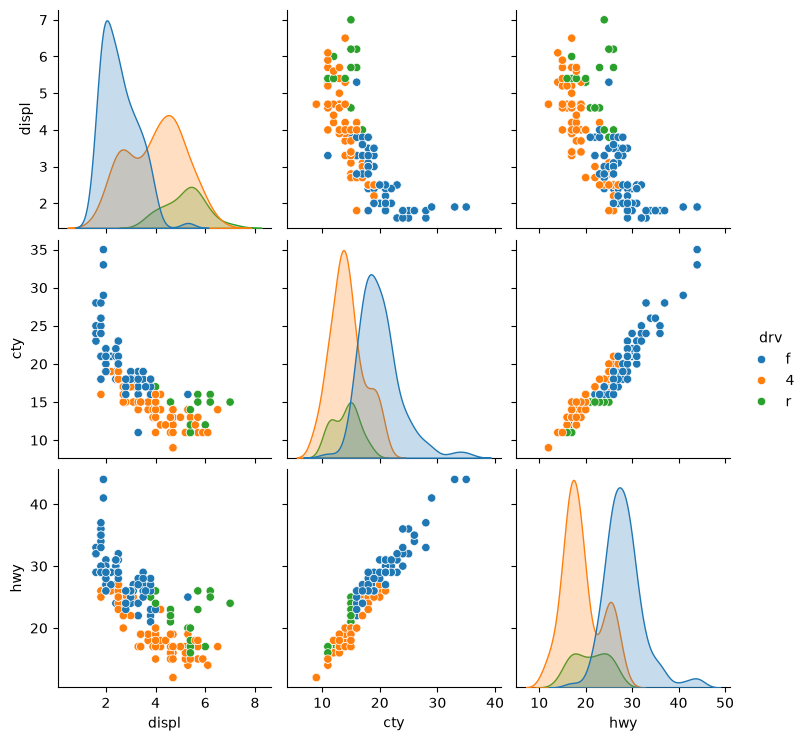

In [9]:
# 네 열만 골라 모든 쌍의 관계 그리기
sns.pairplot(data=mpg[['displ', 'cty', 'hwy', 'drv']], hue='drv')
plt.show()

**기대 출력**

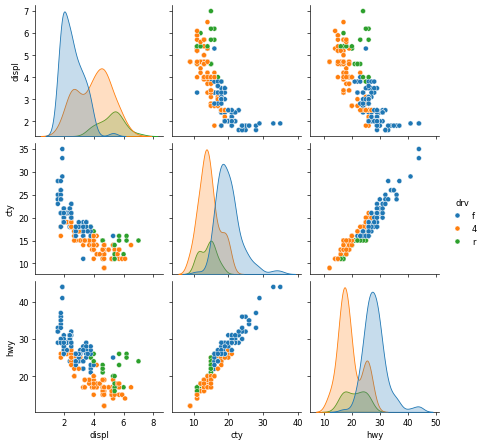


#### 3-2. 구동 방식(`drv`)별로 칸을 나누어 배기량과 고속도로 연비의 산점도를 그리시오.

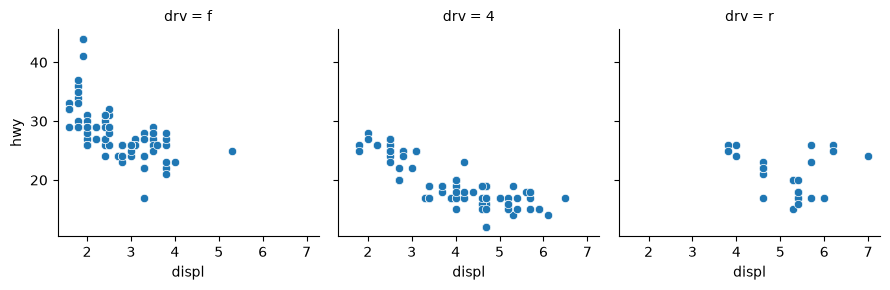

In [10]:
# 구동 방식별로 칸을 나눈 산점도
facet = sns.FacetGrid(mpg, col='drv')
facet.map(sns.scatterplot, 'displ', 'hwy')
plt.show()

**기대 출력**

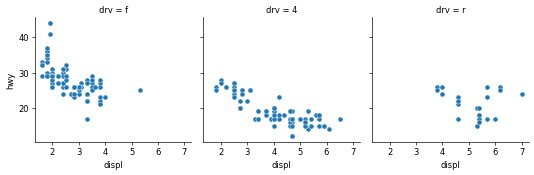


---

## 문제 4. pivot 과 heatmap (제한시간 15분)

#### 4-1. mpg 데이터에서 자동차 종류(`category`)와 구동 방식(`drv`)별 고속도로 연비 평균을 heatmap 으로 그리시오.

- 행은 자동차 종류, 열은 구동 방식
- 각 칸에 평균을 소수점 첫째 자리까지 표시
- 제목은 `Mean Highway MPG by Category and Drive Type`
- heatmap 을 그린 뒤, 사용한 표를 소수점 첫째 자리까지 반올림하여 출력할 것

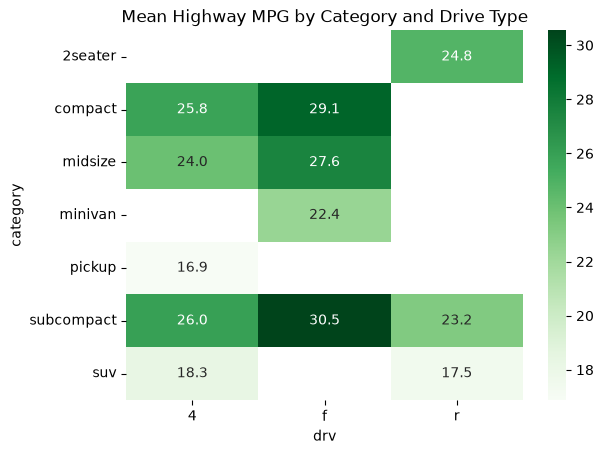

drv            4     f     r
category                    
2seater      NaN   NaN  24.8
compact     25.8  29.1   NaN
midsize     24.0  27.6   NaN
minivan      NaN  22.4   NaN
pickup      16.9   NaN   NaN
subcompact  26.0  30.5  23.2
suv         18.3   NaN  17.5


In [11]:
# 종류와 구동 방식별 평균 구하기
mean_hwy = mpg.groupby(['category', 'drv']).agg(mean_hwy=('hwy', 'mean')).reset_index()

# 표 형태로 바꾸기
hwy_table = mean_hwy.pivot(index='category', columns='drv', values='mean_hwy')

# heatmap 그리기와 제목
sns.heatmap(hwy_table, annot=True, fmt='.1f', cmap='Greens')
plt.title('Mean Highway MPG by Category and Drive Type')
plt.show()

# 표 출력
print(hwy_table.round(1))

**기대 출력**

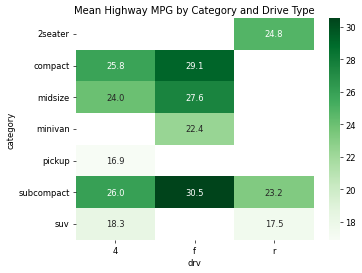

```
drv            4     f     r
category                    
2seater      NaN   NaN  24.8
compact     25.8  29.1   NaN
midsize     24.0  27.6   NaN
minivan      NaN  22.4   NaN
pickup      16.9   NaN   NaN
subcompact  26.0  30.5  23.2
suv         18.3   NaN  17.5
```

#### 4-2. 4-1 의 heatmap 에서 색이 칠해지지 않은 빈 칸이 있음. 빈 칸은 무엇을 의미하는가?

---

##### 답안

- 자동차 종류와 구동 방식의 조합에 해당하는 차량이 데이터에 없어 평균 연비를 계산할 수 없다

#### 4-3. 미국 시애틀의 날씨 데이터에서 월별, 연도별 평균 최고기온을 heatmap 으로 그리시오.

- 아래 셀을 먼저 실행할 것. 날짜에서 연도(`year`)와 월(`month`)을 뽑아 둔 상태임

In [13]:
weather = pd.read_csv('https://raw.githubusercontent.com/vega/vega-datasets/main/data/seattle-weather.csv')
weather['year']  = weather['date'].str[:4].astype(int)
weather['month'] = weather['date'].str[5:7].astype(int)

print(weather[['date', 'year', 'month', 'temp_max', 'weather']].head())

         date  year  month  temp_max  weather
0  2012-01-01  2012      1      12.8  drizzle
1  2012-01-02  2012      1      10.6     rain
2  2012-01-03  2012      1      11.7     rain
3  2012-01-04  2012      1      12.2     rain
4  2012-01-05  2012      1       8.9     rain


- 행은 월(`month`), 열은 연도(`year`), 값은 최고기온(`temp_max`)의 평균
- 각 칸에 평균을 소수점 첫째 자리까지 표시하고, 색상은 `'Reds'` 를 사용
- 제목은 `Mean Max Temperature in Seattle`

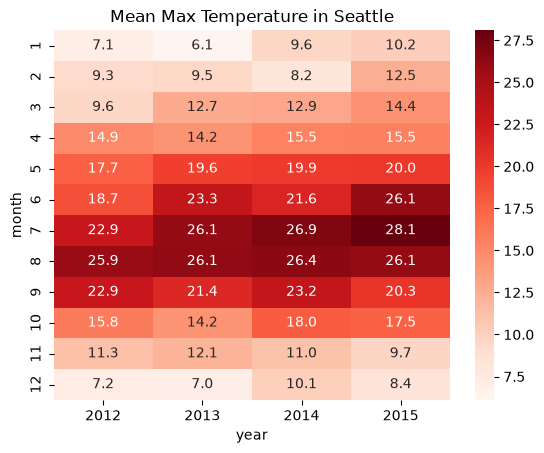

In [14]:
# 월, 연도별 평균 구하기
mean_temp = weather.groupby(['month', 'year']).agg(mean_temp_max=('temp_max', 'mean')).reset_index()

# 표 형태로 바꾸기
temp_table = mean_temp.pivot(index='month', columns='year', values='mean_temp_max')

# heatmap 그리기와 제목
sns.heatmap(temp_table, annot=True, fmt='.1f', cmap='Reds')
plt.title('Mean Max Temperature in Seattle')
plt.show()

**기대 출력**

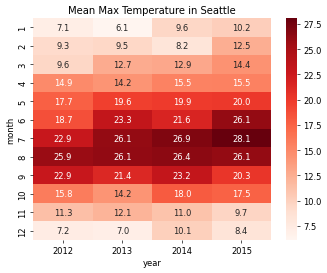
